# 01. Smoke test: sentiment BiGRU
Перший запуск на сервері: середовище, інференс, короткий train-smoke. Ноутбук лише викликає скрипти з `src/`.

In [1]:
import json, os, platform, subprocess, sys
from pathlib import Path
import pandas as pd, torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print("ROOT:", ROOT)
print("python", platform.python_version(), "| torch", torch.__version__, "| cuda", torch.cuda.is_available(), "| cpus", os.cpu_count())

def run(*args):
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print(r.stdout[-3000:])
    if r.returncode: print(r.stderr[-3000:]); raise SystemExit(r.returncode)

ROOT: /home/mykyta/mlops_review_clf
python 3.12.16 | torch 2.15.0+cpu | cuda False | cpus 2


## 1. Наявність файлів

In [2]:
for p in ["models/sentiment_rnn.pt","configs/config.yaml","data/processed/labeled.csv","data/samples/sample_reviews.csv"]:
    f = ROOT/p; print(("OK  " if f.exists() else "MISSING"), p, f"{f.stat().st_size/1e6:.1f} MB" if f.exists() else "")

OK   models/sentiment_rnn.pt 20.0 MB
OK   configs/config.yaml 0.0 MB
OK   data/processed/labeled.csv 3.6 MB
OK   data/samples/sample_reviews.csv 0.2 MB


## 2. Predict smoke
Вердикт за правилом: `p < 0.15` negative, `p >= 0.60` positive, між ними neutral.

In [3]:
run("src/predict.py", "doesn't have any flaws", "i will never come to this bank again",
    "great sound but the battery is bad", "works fine", "the speaker broke after a week")
pd.read_csv("runs/smoke_predict/predictions.csv")[["text","p_positive","entropy","label","oov_share"]]

Правило: p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral
                                text  p_positive  entropy    label  oov_share
              doesn't have any flaws      0.8889   0.5034 positive        0.0
i will never come to this bank again      0.1239   0.5405 negative        0.0
  great sound but the battery is bad      0.4947   0.9999  neutral        0.0
                          works fine      0.9416   0.3211 positive        0.0
      the speaker broke after a week      0.0411   0.2475 negative        0.0

Smoke test completed. Number of results: 5. Saved: /home/mykyta/mlops_review_clf/runs/smoke_predict/predictions.csv



,text,p_positive,entropy,label,oov_share
0,doesn't have any flaws,0.8889,0.5034,positive,0.0
1,i will never come to this bank again,0.1239,0.5405,negative,0.0
2,great sound but the battery is bad,0.4947,0.9999,neutral,0.0
3,works fine,0.9416,0.3211,positive,0.0
4,the speaker broke after a week,0.0411,0.2475,negative,0.0


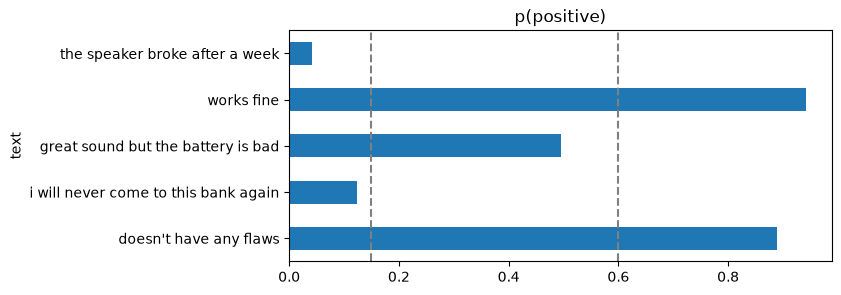

In [4]:
df = pd.read_csv("runs/smoke_predict/predictions.csv")
ax = df.set_index("text")["p_positive"].plot.barh(figsize=(7,3), title="p(positive)")
ax.axvline(0.15, ls="--", c="gray"); ax.axvline(0.60, ls="--", c="gray")

## 3. Train smoke
Одна епоха на малій вибірці, лише щоб переконатися, що пайплайн проходить. Метрики тут ні про що не свідчать.

In [5]:
run("src/train.py", "--smoke")
print(json.dumps(json.load(open("runs/smoke_train/metrics.json")), indent=2, ensure_ascii=False))

Базовий артефакт: sentiment_rnn.pt, словник 4369, dim 300
train 570 (з них наших 150), val 90, test 90
epoch   1/1  loss 0.7068  val macro-F1 0.1667  (26s)
{
  "rule": "p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral",
  "n_train": 570,
  "n_val": 90,
  "n_test": 90,
  "best_val_macro_f1": 0.16666666666666666,
  "test_macro_f1": 0.16666666666666666,
  "test_accuracy": 0.3333333333333333,
  "smoke": true,
  "train_seconds": 27.3,
  "test_auc_pos_vs_neg": 0.8122222222222223
}
Артефакт: /home/mykyta/mlops_review_clf/runs/smoke_train/sentiment_rnn.pt
Train completed. (smoke)

{
  "rule": "p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral",
  "n_train": 570,
  "n_val": 90,
  "n_test": 90,
  "best_val_macro_f1": 0.16666666666666666,
  "test_macro_f1": 0.16666666666666666,
  "test_accuracy": 0.3333333333333333,
  "smoke": true,
  "train_seconds": 27.3,
  "test_auc_pos_vs_neg": 0.8122222222222223
}


## 4. Результати
`runs/smoke_predict/predictions.csv` і `runs/smoke_train/{metrics.json,history.json,sentiment_rnn.pt}`.

In [6]:
for p in sorted((ROOT/"runs").rglob("*")):
    if p.is_file(): print(p.relative_to(ROOT), f"{p.stat().st_size/1e3:.0f} KB")

runs/smoke_predict/predictions.csv 0 KB
runs/smoke_train/history.json 0 KB
runs/smoke_train/metrics.json 0 KB
runs/smoke_train/sentiment_rnn.pt 19991 KB
